# Radio-map extension, round 3: can a meta-learned kriging-attention kernel beat IDW, kriging, ridge+IDW and gradient boosting?



**Needs next to it (all unchanged except the new last one):** `rmbench_core.py`, `rmbench_nn.py`, `rmbench_ext.py`, `rmbench_ext2.py`, `rmbench_ext3.py`, `run_ext.py` and the new **`rmbench_ext4.py`**. DeepMIMO (package + network) is only needed for the optional descriptive `dm_path` family; the UJI / SOD downloads happen if the files are not under `data/`.

## Why this notebook (what rounds 1-2 left open)
| Finding so far | Consequence for this round |
|---|---|
| Label-aware GCN/GAT lose to IDW (6-13 % worse RMSE under random splits). | **Dropped.** No GCN/GAT arms here. |
| KGNN (kriging-initialised message passing) beats IDW by 2-8 %, but its kernel (6 parameters) is learned from 5-100 labels of one unit. | **Idea 1: meta-learn the kernel on other layouts** (`kgnn_prior`, `kgnn_priorft`). |
| `kgnn_side` never beat `rk_side` (ridge + IDW on the same covariates). | **Idea 2: propagation-aware kernel** that uses the side information inside the covariance (`kgnn_prior_sk`), and fixed 50/50 ensembles. |
| A reviewer will ask for a gradient-boosting baseline. | `gb_geo` / `gb_side` (GB on the same covariates + IDW on the out-of-fold residual). |

**"Attention" framing for the paper.** The KGNN prediction at a query is a weighted sum of its K nearest labelled nodes, with weights = the solution of a kriging system built from a learned covariance. That is a one-layer, kernel-based attention whose scores depend on distance, azimuth/range relative to the transmitter and (new) side-information differences. The pre-training is episodic masked-label training across layouts, i.e. the cross-layout generalisation experiment of your plan, with only the kernel transferred.

## Hypotheses (frozen in section 4 before any confirmatory run)
* **H6 (primary, real Wi-Fi, 6 buildings, no side information):** `kgnn_prior` has lower RMSE than `kgnn` (same kernel, learned from scratch on the unit's own labels).
* **H7 (primary, wall simulator, side information, 16 fresh layouts):** `kgnn_prior_sk` has lower RMSE than `rk_side`.
* Secondary: the contrasts in `rmbench_ext4.GEO_C` and `rmbench_ext4.SIDE_C` (printed in full, wins and losses).

## Honest expectations (written before the run)
* H6 is the most plausible win: at 5-10 labels the kernel is the weakest part of KGNN. A gain of a few percent over `kgnn` is the realistic size.
* H7 is the hardest: in the wall simulator the shadowing field does **not** depend on walls (walls only enter the deterministic loss), so the side-aware kernel has little to exploit and `rk_side` is already close to the noise floor. If H7 comes back "not supported", the honest claim is that the meta-learned prior helps without side information, and that ridge+IDW is hard to beat when side information explains the deterministic part of the loss.
* If both primaries fail, the paper's contribution is the bounded statement (standard GNNs lose; KGNN gains 2-8 %; the prior does/does not add; GB and ridge+IDW are strong baselines), which is still a clean, reproducible benchmark.

## 1. Setup

In [1]:
import os, sys, json, warnings, shutil
sys.path.insert(0, os.getcwd())
warnings.filterwarnings("ignore")

def _preflight():
    need = ["rmbench_core.py", "rmbench_nn.py", "rmbench_ext.py", "rmbench_ext2.py", "rmbench_ext3.py", "rmbench_ext4.py", "run_ext.py"]
    gone = [f for f in need if not os.path.exists(f)]
    if gone: raise FileNotFoundError(f"missing next to the notebook ({os.getcwd()}): {gone}")
    ext, ext2, ext3, ext4 = (open(f).read() for f in ("rmbench_ext.py", "rmbench_ext2.py", "rmbench_ext3.py", "rmbench_ext4.py"))
    if "rmbench_ext as rx" in ext: raise RuntimeError("rmbench_ext.py contains later-layer code. Restore the ORIGINAL rmbench_ext.py.")
    if "rmbench_ext as rx" not in ext2 or "rmbench_ext3" in ext2: raise RuntimeError("rmbench_ext2.py is not the second layer.")
    if "rmbench_ext2 as r2" not in ext3 or "rmbench_ext4" in ext3: raise RuntimeError("rmbench_ext3.py is not the third layer.")
    if "rmbench_ext3 as r3" not in ext4: raise RuntimeError("rmbench_ext4.py is not the fourth layer (it should import rmbench_ext3 as r3).")
_preflight()
for _m in ("rmbench_ext", "rmbench_ext2", "rmbench_ext3", "rmbench_ext4"): sys.modules.pop(_m, None)

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
import torch
import rmbench_core as rc, rmbench_ext as rx, rmbench_ext2 as r2, rmbench_ext3 as r3, rmbench_ext4 as r4
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 50)

SMOKE  = False         # True: dry run on FAKE data (UJI-like, SOD-like, 4 wall layouts, no DeepMIMO, 60 pre-training steps). Says nothing about science. Wipes nb4_smoke/.
RUN_DM = True          # optional descriptive family on DeepMIMO (2.5 / 28 / 60 GHz); set False if DeepMIMO is not installed
N_JOBS = max(1, (os.cpu_count() or 2) - 1)
ROOT   = "nb4_smoke" if SMOKE else "results_conf3"
R1, R2 = "results_ext2", "results_conf2"      # earlier rounds: only READ (unit names to exclude, plan hashes). Never written.
if SMOKE: shutil.rmtree(ROOT, ignore_errors=True)
os.makedirs(ROOT, exist_ok=True)
WANT = ["uji", "sod", "wall"] + (["dm_path"] if (RUN_DM and not SMOKE) else [])

S = dict(n_rep=2 if SMOKE else 5, uji_aps=2 if SMOKE else 8, sod_aps=2 if SMOKE else 10,
         min_floors=6 if SMOKE else 13, uji_floors_assert=4 if SMOKE else 8, sod_floors_assert=5,
         n_layouts_wall=4 if SMOKE else 16, n_tx_wall=2 if SMOKE else 6, wall_pts=250 if SMOKE else 500,
         wall_dens=(20, 40, 60) if SMOKE else (20, 50, 100), wall_ntest=100 if SMOKE else 200, max_dm_units=6 if SMOKE else 24,
         prior_steps=60 if SMOKE else 1500, n_src=12 if SMOKE else 40, wall_group=2 if SMOKE else 4)
print("SMOKE" if SMOKE else "REAL", "| jobs:", N_JOBS, "| families:", WANT, "| torch", torch.__version__)

REAL | jobs: 15 | families: ['uji', 'sod', 'wall', 'dm_path'] | torch 2.14.0+cu130


## 2. Data (fresh units wherever the data allow)
* **UJIIndoorLoc**: same data-only setting rule as rounds 1-2; the per-floor AP cap is filled with APs that **neither round used** (`exclude=` unit names read from both earlier caches), seed 3.
* **SODIndoorLoc**: same three buildings as round 2, but APs not used in round 2, seed 3.
* **`wall`**: 16 new layouts (seed 3). The only family where layouts are independent draws by construction; it has side information (walls crossed, LOS).
* **`dm_path`** (optional): DeepMIMO path-sum power at 2.5 / 28 / 60 GHz; the transmitters are the same as before, one environment per scenario, so it is **descriptive only** and has no meta-learned prior (nothing to transfer from).

In [2]:
csv_dir = rx.make_fake_uji(f"{ROOT}/fake_uji", floors=(2, 2, 2), n_waps=12) if SMOKE else rx.fetch_uji("data/ujiindoorloc")
uji_df = r2.read_uji(csv_dir); tab = r2.wifi_floor_table(uji_df, **r2.UJI_COLS)
sug_table, SUG = r2.suggest_wifi_setting(tab, min_floors=S["min_floors"], min_aps=3); print("chosen (same rule as rounds 1-2):", SUG)
EXCL_UJI = set() if SMOKE else r3.units_in_cache(f"{R1}/cache_uji") | r3.units_in_cache(f"{R2}/cache_uji")
print("UJI units used in rounds 1-2 (excluded here):", len(EXCL_UJI), "(0 = earlier caches not found: units are then new only by seed)")
UJI = dict(rx.UJI_CFG, cache_dir=f"{ROOT}/cache_uji", densities=SUG["densities"], n_test=SUG["n_test"], min_unit_points=SUG["min_unit_points"],
           min_det_frac=SUG["min_det_frac"], uji_max_waps_per_floor=S["uji_aps"], n_rep=S["n_rep"], outage_q=(0.25, 0.5), outage_abs_dbm=(), outage_min_class=8,
           trend_policy="robust", seed=3)
ok_uji, rec_uji = r3.build_wifi_units3(uji_df, UJI, "uji", **r2.UJI_COLS, exclude=EXCL_UJI)
display(rec_uji.groupby(["building", "floor", "reason"]).size().unstack(fill_value=0))
meta = pd.DataFrame([dict(unit=n, layout=(u := rx.get_unit_ext(n, UJI["cache_dir"]))["layout"], parent=u["parent"]) for n in ok_uji])
print(f"{len(ok_uji)} UJI units | {meta.parent.nunique()} building-floors | {meta.layout.nunique()} buildings | overlap with earlier rounds: {len(set(ok_uji) & EXCL_UJI)}")
assert not (set(ok_uji) & EXCL_UJI)
assert meta.parent.nunique() >= S["uji_floors_assert"], "too few fresh UJI floors for floor-level inference; read the table above (APs of the thin floors were used up in rounds 1-2)"
FAMILY_DEFS = {"uji": dict(names=ok_uji, cfg=UJI, side=False, by="parent", infer=None)}

chosen (same rule as rounds 1-2): {'densities': (5, 10, 20), 'n_test': 20, 'min_unit_points': 41, 'min_det_frac': 0.3, 'floors_ok': 12, 'reached': False}
UJI units used in rounds 1-2 (excluded here): 185 (0 = earlier caches not found: units are then new only by seed)


reason          cut by per-floor cap  excluded (used in round 1)  kept  too few detected points
building floor                                                                                 
0        0                         0                          16     3                       93
         1                        23                          16     8                      111
         2                        21                          16     8                      126
         3                         0                          16     6                      155
1        0                         0                           9     0                      117
         1                         4                          16     8                      135
         2                         0                          16     3                      163
         3                         0                           0     0                      138
2        0                         0                          16     3                       66
         1                        20                          16     8                       95
         2                        11                          16     8                       83
         3                         8                          16     8                      104
         4                         0                          16     3                      114

66 UJI units | 11 building-floors | 3 buildings | overlap with earlier rounds: 0


In [3]:
SOD_DIR = r3.make_fake_sod(f"{ROOT}/fake_sod") if SMOKE else r3.fetch_sod("data/sodindoorloc")
sod_df = r3.read_sod(SOD_DIR); tab_s = r2.wifi_floor_table(sod_df, **r3.SOD_COLS, wprefix=r3.SOD_PREFIX)
ts_table, SS = r2.suggest_wifi_setting(tab_s, min_floors=S["sod_floors_assert"], min_aps=3)
SOD_DENS = tuple(sorted(set(UJI["densities"]) | {SS["densities"][-1]})); print("SOD densities", SOD_DENS)
EXCL_SOD = set() if SMOKE else r3.units_in_cache(f"{R2}/cache_sod"); print("SOD units used in round 2 (excluded here):", len(EXCL_SOD))
SOD = dict(rx.UJI_CFG, cache_dir=f"{ROOT}/cache_sod", densities=SOD_DENS, n_test=SS["n_test"], min_unit_points=max(SS["min_unit_points"], max(SOD_DENS) + SS["n_test"] + 1),
           min_det_frac=SS["min_det_frac"], uji_max_waps_per_floor=S["sod_aps"], n_rep=S["n_rep"], outage_q=(0.25, 0.5), outage_abs_dbm=(), outage_min_class=8,
           trend_policy="robust", seed=3)
ok_sod, rec_sod = r3.build_wifi_units3(sod_df, SOD, "sod", **r3.SOD_COLS, wprefix=r3.SOD_PREFIX, exclude=EXCL_SOD)
display(rec_sod.groupby(["building", "floor", "reason"]).size().unstack(fill_value=0))
metaS = pd.DataFrame([dict(unit=n, layout=(u := rx.get_unit_ext(n, SOD["cache_dir"]))["layout"], parent=u["parent"]) for n in ok_sod])
print(f"{len(ok_sod)} SOD units | {metaS.parent.nunique()} building-floors | {metaS.layout.nunique()} buildings | overlap with round 2: {len(set(ok_sod) & EXCL_SOD)}")
assert not (set(ok_sod) & EXCL_SOD); assert metaS.parent.nunique() >= S["sod_floors_assert"], "SOD should give 5 building-floors"
FAMILY_DEFS["sod"] = dict(names=ok_sod, cfg=SOD, side=False, by="parent", infer=None)

SOD densities (5, 10, 20, 60)
SOD units used in round 2 (excluded here): 50


reason          cut by per-floor cap  excluded (used in round 1)  kept  too few detected points
building floor                                                                                 
1        1                        12                          10    10                       11
         2                        13                          10    10                       13
         3                         6                          10    10                        3
2        4                         0                          10     7                       39
3        4                        10                          10    10                       16

47 SOD units | 5 building-floors | 3 buildings | overlap with round 2: 0


In [4]:
WALL = dict(rc.DEFAULT_CFG, cache_dir=f"{ROOT}/cache_wall", densities=S["wall_dens"], n_test=S["wall_ntest"], n_rep=S["n_rep"], min_unit_points=300,
            outage_q=(0.1, 0.25), outage_abs_dbm=(), outage_min_class=8, trend_policy="robust", seed=3)
ok_wall = r2.build_wall_units(WALL, S["n_layouts_wall"], S["n_tx_wall"], seed=3, n_pts=S["wall_pts"])
FAMILY_DEFS["wall"] = dict(names=ok_wall, cfg=WALL, side=True, by="layout", infer=None)
print(len(ok_wall), "wall units in", S["n_layouts_wall"], "layouts")
if "dm_path" in WANT:
    DM_SCENARIOS, DM_INFER = ["i1_2p5", "i2_28b", "i3_60"], ["i1_2p5"]
    cfg = dict(rc.DEFAULT_CFG, cache_dir=f"{ROOT}/cache_dm_path", power_def="path_sum", outage_q=(0.1, 0.25), outage_abs_dbm=(), outage_min_class=8, trend_policy="robust", seed=1)
    try:
        names, dropped = rx.build_dm_units(DM_SCENARIOS, cfg)
        for n, why in dropped: print("dropped:", n, "-", why)
        by = rx.layouts_of(names, cfg["cache_dir"]); names = [n for v in by.values() for n in v[:S["max_dm_units"]]]
        if names: FAMILY_DEFS["dm_path"] = dict(names=names, cfg=dict(cfg, densities=(30, 100, 300), n_test=1000, n_rep=S["n_rep"]), side=True, by="parent", infer=DM_INFER)
    except Exception as e:
        print("DeepMIMO family skipped:", type(e).__name__, str(e)[:200])
display(r2.layout_summary(FAMILY_DEFS))

96 wall units in 16 layouts
Scenario "i1_2p5" already exists in /home/praaneshnair/gitProjects/prism/deepmimo_scenarios
Loading TXRX PAIR: TXset 2 (tx_idx 0) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 1) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 2) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 3) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 4) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 5) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 6) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 7) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 8) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 9) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 10) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 11) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 12) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 13) & RXset 0 (rx_idxs 

,units,parents,layouts
family,,,
dm_path,27,27,3
sod,47,5,3
uji,66,11,3
wall,96,16,16


## 3. Checks of the new code (run before trusting any number)
1. `KGNNP` with no side kernel is **numerically identical** to `rmbench_nn.KGNN` for the same parameters, and the side kernel with weights -> 0 reduces to it.
2. Side kernel is a valid covariance: the kriging matrix stays positive definite on a real unit (smallest eigenvalue > 0).
3. **Label-leak test** for every new method: corrupt the test labels with 50 dB noise; the predictions must be bit-identical.
4. **Held-out layouts really are held out**: no evaluation unit of a group appears in that group's source set; the saved prior is trained without it.
5. A tiny pre-training run gives a finite, loadable prior (this also exercises `plan_groups`, episode building and `pretrain_kernel`).

In [5]:
from rmbench_nn import KGNN, _isp
# 1. identical to KGNN, and side kernel off at w -> 0
torch.manual_seed(0); a = KGNN(polar=True, s2_init=0.3); b = r4.KGNNP(polar=True, s2_init=0.3, n_side=0); b.load_state_dict(a.state_dict())
Pq, Pr, yr, tx = torch.randn(7, 2) * 5, torch.randn(20, 2) * 5, torch.randn(20), torch.tensor([1.0, -2.0])
with torch.no_grad(): ya, yb = a(Pq, Pr, yr, 2.0, tx, 8), b(Pq, Pr, yr, 2.0, tx, 8)
assert torch.allclose(ya, yb, atol=1e-6), (ya - yb).abs().max(); print("KGNNP(n_side=0) == KGNN: OK")
c = r4.KGNNP(polar=True, s2_init=0.3, n_side=2); c.load_state_dict({**b.state_dict(), "ws": torch.full((2,), -30.0)})
with torch.no_grad(): yc = c(Pq, Pr, yr, 2.0, tx, 8, torch.randn(7, 2), torch.randn(20, 2))
assert torch.allclose(ya, yc, atol=1e-4), (ya - yc).abs().max(); print("side kernel with w -> 0 == KGNN: OK")

# 2. positive definiteness of the side-aware covariance on a real wall unit
u0 = rx.get_unit_ext(FAMILY_DEFS["wall"]["names"][0], WALL["cache_dir"]); tr0, te0 = r2.split_for2(u0, WALL["densities"][0], 0, WALL["n_test"], "random", 0.0, "chk")
uu, spec = r2.view_for_split2(u0, tr0); pp = r2.prepare2(uu, tr0, "geo_side", WALL["clip"], spec); Ss = torch.tensor(r4.side_cols(uu, pp)[tr0], dtype=torch.float32); Pp = torch.tensor(uu["pos"][tr0], dtype=torch.float32)
m = r4.KGNNP(n_side=Ss.shape[1], w_init=0.5)
with torch.no_grad(): Cm = m.cov(Pp[:, None, :] / 5 - Pp[None, :, :] / 5, torch.zeros(len(Pp), len(Pp)), torch.zeros(len(Pp), len(Pp)), Ss[:, None, :] - Ss[None, :, :])
print("side-aware covariance, min eigenvalue:", float(torch.linalg.eigvalsh(Cm + 1e-6 * torch.eye(len(Pp))).min()), "(must be > 0)"); assert float(torch.linalg.eigvalsh(Cm + 1e-6 * torch.eye(len(Pp))).min()) > 0

# 3-5. leak test, held-out layouts, tiny pre-training (wall family, two groups)
r4.install(); mem = {"wall": dict(FAMILY_DEFS["wall"], cfg=dict(WALL, test_salt="chk"))}
plan = r4.plan_groups(mem, group_size=S["wall_group"], n_src=S["n_src"])
for p in plan:
    ev, src = {it["name"] for it in p["eval"]}, {it["name"] for it in p["source"]}; assert not ev & src and not {it["layout"] for it in p["eval"]} & {it["layout"] for it in p["source"]}
print("plan:", [(p["gid"], len(p["eval"]), len(p["source"])) for p in plan], "-> eval/source disjoint by unit AND by layout: OK")
p0 = plan[0]; srcs = [(it["name"], it["cfg"]) for it in p0["source"][:12]]; PTH = {}
for var in ("geo", "rid", "sk"):
    eps = r4.build_prior_episodes(srcs, var, reps=1); assert eps, var
    PTH[var] = r4.pretrain_kernel(eps[:-2], eps[-2:], 15, 0, f"{ROOT}/chk_prior_{var}.pt", log=lambda *a: None)
    sd = torch.load(PTH[var]); assert all(torch.isfinite(v).all() for v in sd.values()), var
print("tiny priors trained and finite:", {k: os.path.basename(v) for k, v in PTH.items()})
rng = np.random.default_rng(1); ue = p0["eval"][0]; u0 = rx.get_unit_ext(ue["name"], WALL["cache_dir"])
tr, te = r2.split_for2(u0, WALL["densities"][0], 0, WALL["n_test"], "random", 0.0, "chk"); bad = {k: (v.copy() if isinstance(v, np.ndarray) else v) for k, v in u0.items()}
bad["y"][te] = bad["y"][te] + rng.normal(0, 50, len(te)); out = {}
def _pred(j, uu, tr, te, P):
    hp = j.get("hp", {})
    if j["method"] == "rk_side": return r2.predict_rk_side(uu, tr, te, P["geo_side"], hp)[0]
    return rc.predict_method(j["method"], hp, uu, tr, te, P[hp.get("fset", "geo")], 7, {})[0]
for tag, uu0 in (("clean", u0), ("corrupt", bad)):
    uu, spec = r2.view_for_split2(uu0, tr); P = {fs: r2.prepare2(uu, tr, fs, WALL["clip"], spec) for fs in ("geo", "geo_side")}
    for j in r4.conf4_jobs(True, PTH):
        if j["method"] != "trend": out[(tag, j["name"])] = _pred(j, uu, tr, te, P)
for nm in sorted({k[1] for k in out}): print(f"{nm:18s} leak test:", "PASS" if np.array_equal(out[("clean", nm)], out[("corrupt", nm)]) else "FAIL")
assert all(np.array_equal(out[("clean", n)], out[("corrupt", n)]) for n in {k[1] for k in out}), "a method uses test labels"

KGNNP(n_side=0) == KGNN: OK
side kernel with w -> 0 == KGNN: OK
side-aware covariance, min eigenvalue: 0.03145035356283188 (must be > 0)
plan: [('g0_wall_L07-wall_L03-wall_L13-wall_L12', 24, 40), ('g1_wall_L02-wall_L06-wall_L14-wall_L10', 24, 40), ('g2_wall_L04-wall_L00-wall_L08-wall_L01', 24, 40), ('g3_wall_L05-wall_L09-wall_L11-wall_L15', 24, 40)] -> eval/source disjoint by unit AND by layout: OK
tiny priors trained and finite: {'geo': 'chk_prior_geo.pt', 'rid': 'chk_prior_rid.pt', 'sk': 'chk_prior_sk.pt'}
ens_side           leak test: PASS
ens_sk             leak test: PASS
gb_side            leak test: PASS
idw                leak test: PASS
kgnn               leak test: PASS
kgnn_prior         leak test: PASS
kgnn_prior_rid     leak test: PASS
kgnn_prior_sk      leak test: PASS
kgnn_priorft       leak test: PASS
kgnn_priorft_sk    leak test: PASS
kgnn_side          leak test: PASS
krig_global        leak test: PASS
krig_side          leak test: PASS
rk_side            leak test: P

## 4. Pre-registration (write once, before any confirmatory result)
Frozen here: contrast lists, primaries, densities, replicate ids, test salt, pre-training protocol, datasets, both splits, the claim rule **and the wording rule** (what the paper may say for each outcome). The file is hashed; re-running with the same plan is a no-op, a different plan raises. **Commit `prereg_conf3.json` to git before running section 5.**

What was designed after seeing earlier results is listed in the file itself: the whole idea (prior, side kernel, GB baseline, ensembles) follows rounds 1-2; what is fresh is the **data** (new UJI / SOD APs, 16 new wall layouts, new test salt, new replicate ids), not the hypotheses.

In [6]:
r1_sha = json.load(open(f"{R1}/prereg.json"))["sha256"] if os.path.exists(f"{R1}/prereg.json") else None
r2_sha = json.load(open(f"{R2}/prereg_conf2.json"))["sha256"] if os.path.exists(f"{R2}/prereg_conf2.json") else None
SPECS = {t: r3.family_spec(fd, claim_eligible=(t == "wall")) for t, fd in FAMILY_DEFS.items()}
POOL_MEMBERS = ["uji", "sod"]; POOL_DENS = tuple(sorted(set(UJI["densities"]) & set(SOD["densities"])))
SPECS["real_wifi"] = r3.pooled_spec(SPECS, POOL_MEMBERS, POOL_DENS)
FAKE = {"geo": "x", "rid": "x", "sk": "x"}
PRE_SPEC = dict(
    title="radio-map extension, round 3: meta-learned kriging-attention prior, side-aware kernel, GB baseline",
    earlier_prereg_sha256=dict(round1=r1_sha, round2=r2_sha),
    designed_after_seeing=["the whole idea (meta-learned kernel prior, propagation-aware kernel, ensembles, GB baseline) follows rounds 1-2",
                           "the primaries H6 and H7", "the 2% equivalence margin and minimum-n rules are inherited from round 2"],
    fresh=dict(test_salt="conf3", reps="300..", uji="APs not used in rounds 1-2, seed 3", sod="APs not used in round 2, seed 3", wall="new layouts (seed 3)",
               dm_path="NOT fresh units; descriptive only; no prior (one environment per scenario)"),
    test_salt="conf3", reps=list(range(300, 300 + S["n_rep"])), splits=["random", "blocked"], block_buffer=0.0, trend_policy="robust",
    tuning="none: library defaults (Kmax=12, s2_init=0.3). The prior is trained on OTHER layouts only; no hyper-parameter is chosen on any evaluation unit.",
    prior=dict(steps=S["prior_steps"], n_src=S["n_src"], batch=4, lr=5e-3, finetune_steps=30, episode_reps=2, episode_rep_ids="500+ (disjoint from evaluation reps)",
               group_size=dict(real_wifi=1, wall=S["wall_group"]), pooled_real_prior="UJI and SOD buildings are pooled: a held-out building is predicted by a prior trained on the other 5"),
    methods=dict(geo=[j["name"] for j in r4.conf4_jobs(False, FAKE)], side=[j["name"] for j in r4.conf4_jobs(True, FAKE)]),
    contrasts_krig=r4.GEO_C, contrasts_side2=r4.SIDE_C, primary=r4.PRIMARY,
    equivalence_margin_pct=r3.EQUIV_MARGIN_PCT, min_parents_for_equivalence=r3.MIN_PARENTS_EQUIV, min_layouts_for_claim=r3.MIN_LAYOUTS_CLAIM,
    families=SPECS, pooled=dict(name="real_wifi", members=POOL_MEMBERS, densities=list(POOL_DENS)),
    holm="one family per (dataset, split, contrast list); cap = contrasts x densities x inference scenarios",
    claim_rule=("A contrast (A,B) is SUPPORTED for a claim-eligible family only if, in EVERY split and at EVERY density of that family, it is Holm-significant at parent level "
                "in the claimed direction AND the layout-level cluster-bootstrap 95% CI excludes 0 in the same direction (needs >= 5 layouts). EQUIVALENT only if the 95% CI of the "
                "relative RMSE difference lies inside +/- margin in every cell (needs >= 8 parents). Anything else is NOT SUPPORTED."),
    wording_rule=dict(SUPPORTED_A_better="the paper may state that A improves on B on this family, with the per-density effect sizes and the layout-level CI",
                      EQUIVALENT="the paper must say A matches B within the margin",
                      NOT_SUPPORTED="the paper must say the advantage was not established; per-cell wins may be shown but not called confirmed",
                      SUPPORTED_A_worse="the paper must report that A is worse"),
    claims=["H6 (primary): kgnn_prior has lower RMSE than kgnn", "H7 (primary): kgnn_prior_sk has lower RMSE than rk_side",
            "Secondary: every contrast in contrasts_krig / contrasts_side2", "Nothing else is tested confirmatorily; any other contrast is exploratory and labelled so."])
PRE_REC = r2.write_prereg(PRE_SPEC, f"{ROOT}/prereg_conf3.json"); PRE = r2.load_prereg(f"{ROOT}/prereg_conf3.json")
print("written", PRE_REC["created_utc"], "sha256", PRE_REC["sha256"][:16])
display(pd.DataFrame(PRE["families"]).T)
rows = []
for tag, fd in FAMILY_DEFS.items():
    nd, nr, ns, nm = len(fd["cfg"]["densities"]), len(PRE["reps"]), len(PRE["splits"]), len(PRE["methods"]["side" if fd["side"] else "geo"]) + (0 if tag == "dm_path" else (5 if fd["side"] else 2))
    rows.append(dict(family=tag, units=len(fd["names"]), methods_incl_prior=nm, job_rows=len(fd["names"]) * nd * nr * nm * ns))
display(pd.DataFrame(rows))

written 2026-10-13T10:51:59.356084Z sha256 63ebe2012b6370c2


,claim_eligible,densities,infer,n_layouts,n_parents,n_test,n_units,side,pooled_from
dm_path,False,"[30, 100, 300]",[i1_2p5],3,27,1000,27,True,NaN
real_wifi,True,"[5, 10, 20]",None,6,16,per member,113,False,"[uji, sod]"
sod,False,"[5, 10, 20, 60]",None,3,5,40,47,False,NaN
uji,False,"[5, 10, 20]",None,3,11,20,66,False,NaN
wall,True,"[20, 50, 100]",None,16,16,200,96,True,NaN


,family,units,methods_incl_prior,job_rows
0,uji,66,10,19800
1,sod,47,10,18800
2,wall,96,20,57600
3,dm_path,27,15,12150


## 5. Run (resumable)
For each family and split: **(a)** pre-train the kernel prior once per held-out group of layouts (three variants where there is side information: `geo`, `rid` = ridge + geo kernel, `sk` = ridge + side kernel); priors are files under `results_conf3/<family>/priors_<split>/`; **(b)** evaluate every method on the held-out layouts only. Real Wi-Fi uses one pooled prior set over the 6 buildings (leave-one-building-out). `RUN_ONLY` runs one family first.

In [7]:
RUN_ONLY = None            # e.g. ["wall"]
RESULTS = {}
GROUPS = [("real", {t: FAMILY_DEFS[t] for t in ("uji", "sod")}, 1, True), ("wall", {"wall": FAMILY_DEFS["wall"]}, S["wall_group"], True)] + \
         ([("dm", {"dm_path": FAMILY_DEFS["dm_path"]}, 1, False)] if "dm_path" in FAMILY_DEFS else [])
for name, members, gsize, with_prior in GROUPS:
    if RUN_ONLY and not set(members) & set(RUN_ONLY): continue
    for split in PRE["splits"]:
        print(f"\n######## {name} | {split}")
        res = r4.run_prior_family(members, split, ROOT, PRE, N_JOBS, name, group_size=gsize, steps=PRE["prior"]["steps"], n_src=PRE["prior"]["n_src"], with_prior=with_prior)
        for t, df in res.items(): RESULTS[(t, split)] = df


######## real | random
[real|random] groups: [('uji_b2', 30, 40), ('sod_b1', 30, 40), ('uji_b1', 11, 40), ('sod_b3', 10, 40), ('sod_b2', 7, 40), ('uji_b0', 25, 40)]
  pretraining prior uji_b2 / geo on 40 source units
    prior uji_b2__geo.pt step 300/1500 val=0.3950 best=0.3950 (step0 0.4069) 1s
    prior uji_b2__geo.pt step 600/1500 val=0.3779 best=0.3779 (step0 0.4069) 2s
    prior uji_b2__geo.pt step 900/1500 val=0.3592 best=0.3592 (step0 0.4069) 3s
    prior uji_b2__geo.pt step 1200/1500 val=0.3571 best=0.3571 (step0 0.4069) 5s
    prior uji_b2__geo.pt step 1500/1500 val=0.3562 best=0.3558 (step0 0.4069) 6s
  pretraining prior sod_b1 / geo on 40 source units
    prior sod_b1__geo.pt step 300/1500 val=0.5217 best=0.5217 (step0 0.5962) 1s
    prior sod_b1__geo.pt step 600/1500 val=0.5169 best=0.5139 (step0 0.5962) 2s
    prior sod_b1__geo.pt step 900/1500 val=0.5155 best=0.5133 (step0 0.5962) 3s
    prior sod_b1__geo.pt step 1200/1500 val=0.5147 best=0.5080 (step0 0.5962) 5s
    pri

## 6. Results
Every pre-specified contrast is printed, wins **and** losses. `rel_gain_pct > 0` means A has lower RMSE than B; CIs are bootstrap over parents (in % of B's RMSE). `verdict` = Holm test plus the 2 % equivalence margin.

In [8]:
PCS, CLS, ENTRIES = {}, {}, []
def analyse(tag, split, df, fd):
    PCS[(tag, split)], CLS[(tag, split)] = r3.report_conf2(df, tag, split, fd, os.path.join(ROOT, tag), PRE)
    for k, pc in PCS[(tag, split)].items():
        if pc is not None and len(pc): ENTRIES.append((tag, split, k, pc))
for (tag, split), df in RESULTS.items(): analyse(tag, split, df, FAMILY_DEFS[tag])
POOL_FD = dict(side=False, infer=None)
for split in PRE["splits"]:
    mem = {t: RESULTS[(t, split)] for t in PRE["pooled"]["members"] if (t, split) in RESULTS}
    if len(mem) == len(PRE["pooled"]["members"]):
        RESULTS[("real_wifi", split)] = r3.pool_real(mem, PRE["pooled"]["densities"]); analyse("real_wifi", split, RESULTS[("real_wifi", split)], POOL_FD)


##### uji_random: 7920 job rows, 7920 ok, 0 failed

=== rmse, parent-level mean (all methods)
name              ens_geo  gb_geo    idw   kgnn  kgnn_prior  kgnn_priorft  krig_global   trend
scenario density                                                                              
uji      5          9.367  12.753  9.622  9.310       9.150         9.136        9.730  10.478
         10         7.472   9.009  7.610  7.454       7.511         7.505        7.789   8.265
         20         6.664   8.016  6.718  6.710       6.733         6.725        6.761   7.137

=== uji_random_krig | rmse | CONFIRMATORY | 21 tests, Holm over all (rel_gain>0: A better; CI in % of RMSE_B)
   scenario  density             A            B  n_units  rel_gain_pct  ci_lo_pct  ci_hi_pct  p_holm                           verdict  underpowered
0       uji        5    kgnn_prior         kgnn       11         1.716      0.501      2.906   0.293                      inconclusive         False
1       uji       10 

### 6a. Relative RMSE gain of the proposal, per family, density and split (`*` = Holm-significant)

In [9]:
for tag in [t for t in PRE["families"] if any((t, s) in PCS for s in PRE["splits"])]:
    for kind, lst in (("krig", PRE["contrasts_krig"]), ("side", PRE["contrasts_side2"])):
        pcs = {s: PCS[(tag, s)][kind] for s in PRE["splits"] if (tag, s) in PCS and PCS[(tag, s)].get(kind) is not None and len(PCS[(tag, s)][kind])}
        if pcs: print("\n", tag, "|", kind, " (relative RMSE gain of A over B in %, '*' = Holm-significant)"); display(rc.variant_table(pcs, [tuple(c) for c in lst]))


 dm_path | side  (relative RMSE gain of A over B in %, '*' = Holm-significant)


density                                  30       100      300
scenario contrast            variant                          
i1_2p5   ens_side vs rk_side blocked  +1.2%*   +1.1%*   +0.9%*
                             random   +2.5%*   +3.6%*   +3.8%*
         rk_side vs gb_side  blocked   +2.5%    -1.3%    -7.7%
                             random    -0.9%  -10.3%*  -11.0%*


 real_wifi | krig  (relative RMSE gain of A over B in %, '*' = Holm-significant)


density                                           5        10       20
scenario  contrast                  variant                           
real_wifi ens_geo vs kgnn           blocked    -1.2%    -0.8%    -1.7%
                                    random     -0.5%    -0.6%    +0.2%
          kgnn vs gb_geo            blocked  +17.9%*    +4.5%    +3.5%
                                    random   +26.5%*  +15.0%*  +13.6%*
          kgnn_prior vs gb_geo      blocked  +19.0%*    +3.0%    -1.9%
                                    random   +26.9%*  +12.6%*   +10.6%
          kgnn_prior vs idw         blocked    +4.8%    +1.1%    -1.0%
                                    random     +3.6%    +0.0%    -2.2%
          kgnn_prior vs kgnn        blocked    +1.3%    -1.5%   -5.6%*
                                    random     +0.5%    -2.9%    -3.5%
          kgnn_prior vs krig_global blocked   +4.7%*    +1.5%    -1.5%
                                    random    +6.9%*    +2.1%    -1.8%
          kgnn_priorft vs kgnn      blocked    +1.2%    -1.7%   -5.5%*
                                    random     +0.9%    -2.8%    -3.3%


 sod | krig  (relative RMSE gain of A over B in %, '*' = Holm-significant)


...

density                                          5        10       20
scenario contrast                  variant                           
uji      ens_geo vs kgnn           blocked    -0.8%    -0.1%    -1.3%
                                   random     -0.6%    -0.2%    +0.7%
         kgnn vs gb_geo            blocked  +18.1%*    +5.7%    +5.7%
                                   random   +27.0%*  +17.3%*  +16.3%*
         kgnn_prior vs gb_geo      blocked  +19.5%*    +5.7%    +2.1%
                                   random   +28.3%*  +16.6%*  +16.0%*
         kgnn_prior vs idw         blocked    +4.5%    +1.2%    -0.1%
                                   random     +4.9%    +1.3%    -0.2%
         kgnn_prior vs kgnn        blocked    +1.6%    -0.0%   -3.7%*
                                   random     +1.7%    -0.8%    -0.3%
         kgnn_prior vs krig_global blocked    +5.0%    +2.7%    +1.2%
                                   random    +6.0%*    +3.6%    +0.4%
         kgnn_priorft vs kgnn      blocked    +1.6%    -0.2%   -3.6%*
                                   random     +1.9%    -0.7%    -0.2%


 wall | krig  (relative RMSE gain of A over B in %, '*' = Holm-significant)


density                                        20      50      100
scenario contrast                  variant                        
wall     kgnn_prior vs idw         blocked  +5.6%*  +3.1%*  +2.9%*
                                   random   +4.1%*  +3.4%*  +2.8%*
         kgnn_prior vs kgnn        blocked   +0.0%   -0.1%   -0.0%
                                   random    -0.0%   +0.4%   +0.4%
         kgnn_prior vs krig_global blocked  +3.2%*   +1.2%   -0.3%
                                   random   +3.1%*  +1.5%*  +1.3%*
         kgnn_priorft vs kgnn      blocked   +0.1%   -0.1%   -0.0%
                                   random    +0.1%   +0.4%   +0.5%


 wall | side  (relative RMSE gain of A over B in %, '*' = Holm-significant)


density                                                20       50      100
scenario contrast                         variant                          
wall     ens_side vs rk_side              blocked    -0.1%    -0.1%   +0.6%
                                          random     +0.0%   +0.9%*  +1.5%*
         ens_sk vs rk_side                blocked    -0.1%    -0.2%   +0.0%
                                          random     -0.0%    -0.1%   -0.1%
         kgnn_prior_rid vs kgnn_side      blocked    -0.0%    +0.1%   -0.9%
                                          random     -0.4%   -3.1%*  -5.1%*
         kgnn_prior_sk vs gb_side         blocked    +8.1%    +6.9%   +5.4%
                                          random   +11.5%*  +10.6%*  +7.0%*
         kgnn_prior_sk vs kgnn_prior_rid  blocked    +0.0%    -0.0%  -0.1%*
                                          random    +0.5%*   +1.1%*  +1.3%*
         kgnn_prior_sk vs kgnn_side       blocked    -0.0%    +0.1%   -1.0%
                                          random     +0.0%   -2.0%*  -3.8%*
         kgnn_prior_sk vs rk_side         blocked    -0.3%   -0.7%*   -0.6%
                                          random    -0.6%*   -1.5%*  -2.5%*
         kgnn_priorft_sk vs kgnn_prior_sk blocked    +0.0%    +0.0%  +0.1%*
                                          random    -0.0%*   +0.2%*  +0.7%*
         rk_side vs gb_side               blocked    +8.4%    +7.6%   +5.9%
                                          random   +12.0%*  +11.9%*  +9.3%*

### 6b. Building-level view of the pooled real data (buildings are the independent unit; 6 buildings -> smallest exact sign-test p = 0.031)

In [10]:
for split in PRE["splits"]:
    if ("real_wifi", split) not in RESULTS: continue
    df = RESULTS[("real_wifi", split)]
    for A, B in (("kgnn_prior", "kgnn"), ("kgnn_prior", "idw"), ("kgnn_priorft", "kgnn")):
        print(f"\n=== real_wifi | {split}: relative RMSE gain (%) of {A} over {B} per building"); display(r3.per_layout_gain(df, A, B))
    cl = CLS[("real_wifi", split)]; display(cl[cl.A.eq("kgnn_prior") & cl.B.eq("kgnn")].round(3))


=== real_wifi | random: relative RMSE gain (%) of kgnn_prior over kgnn per building


density             5      10     20
scenario  layout                    
real_wifi sod_b1 -5.55 -12.28 -16.17
          sod_b2  4.87  -1.50  -1.10
          sod_b3 -1.14  -5.07 -11.35
          uji_b0  2.81  -0.02   0.30
          uji_b1  2.14  -1.98  -0.54
          uji_b2  0.67  -0.88  -0.82


=== real_wifi | random: relative RMSE gain (%) of kgnn_prior over idw per building


density             5     10    20
scenario  layout                  
real_wifi sod_b1 -2.33 -5.43 -9.54
          sod_b2  7.42  3.62 -1.38
          sod_b3  1.35 -3.83 -6.30
          uji_b0  5.19  2.73  0.33
          uji_b1  5.29  4.73  4.11
          uji_b2  4.52 -1.46 -2.64


=== real_wifi | random: relative RMSE gain (%) of kgnn_priorft over kgnn per building


...


=== real_wifi | blocked: relative RMSE gain (%) of kgnn_prior over idw per building


density             5      10    20
scenario  layout                   
real_wifi sod_b1  4.87  -3.09 -7.00
          sod_b2  8.80  11.45  3.02
          sod_b3  3.48  -2.20 -0.71
          uji_b0  9.26   2.08 -2.28
          uji_b1 -0.94  -1.45 -1.26
          uji_b2  3.77   2.45  2.94


=== real_wifi | blocked: relative RMSE gain (%) of kgnn_priorft over kgnn per building


density             5     10     20
scenario  layout                   
real_wifi sod_b1  0.84 -8.87 -17.05
          sod_b2 -0.34  3.51   0.22
          sod_b3 -0.18 -6.65  -5.34
          uji_b0  4.46  0.64  -3.60
          uji_b1 -2.60 -1.51  -4.00
          uji_b2  1.94  0.01  -3.39

,scenario,density,A,B,n_layouts,n_parents,layouts_A_better,mean_delta_layout,rel_gain_pct_layout,ci_lo,ci_hi,sign_p,ci_excludes_0
0,real_wifi,5,kgnn_prior,kgnn,6,16,4,0.047,0.420,-0.216,0.277,0.688,False
7,real_wifi,10,kgnn_prior,kgnn,6,16,3,-0.168,-1.689,-0.501,0.144,1.000,False
14,real_wifi,20,kgnn_prior,kgnn,6,16,1,-0.448,-5.081,-0.846,-0.143,0.219,True


### 6c. Claim evaluation, exactly as written in the plan

In [11]:
CLAIMS = r4.evaluate_claims4(PCS, CLS, PRE); CLAIMS.to_csv(f"{ROOT}/claims_conf3.csv", index=False); display(CLAIMS)
print("\nPRIMARY contrasts:"); display(CLAIMS[CLAIMS.primary])

,family,A,B,primary,status,cells,better,worse,equiv,open,missing
0,real_wifi,kgnn_prior,kgnn,True,NOT SUPPORTED,6,0,1,0,5,0
1,real_wifi,kgnn_priorft,kgnn,False,NOT SUPPORTED,6,0,1,0,5,0
2,real_wifi,kgnn_prior,idw,False,NOT SUPPORTED,6,0,0,0,6,0
3,real_wifi,kgnn_prior,krig_global,False,NOT SUPPORTED,6,2,0,0,4,0
4,real_wifi,ens_geo,kgnn,False,NOT SUPPORTED,6,0,0,4,2,0
5,real_wifi,kgnn_prior,gb_geo,False,NOT SUPPORTED,6,3,0,0,3,0
6,real_wifi,kgnn,gb_geo,False,NOT SUPPORTED,6,4,0,0,2,0
7,wall,kgnn_prior,kgnn,True,EQUIVALENT (+/-2%),6,0,0,6,0,0
8,wall,kgnn_priorft,kgnn,False,EQUIVALENT (+/-2%),6,0,0,6,0,0
9,wall,kgnn_prior,idw,False,SUPPORTED: A better,6,6,0,0,0,0



PRIMARY contrasts:


,family,A,B,primary,status,cells,better,worse,equiv,open,missing
0,real_wifi,kgnn_prior,kgnn,True,NOT SUPPORTED,6,0,1,0,5,0
7,wall,kgnn_prior,kgnn,True,EQUIVALENT (+/-2%),6,0,0,6,0,0
11,wall,kgnn_prior_sk,rk_side,True,NOT SUPPORTED,6,0,4,2,0,0


### 6d. Result-to-wording (mechanical, from the rule frozen in section 4)

In [12]:
rule = {"SUPPORTED: A better": PRE["wording_rule"]["SUPPORTED_A_better"], "NOT SUPPORTED": PRE["wording_rule"]["NOT_SUPPORTED"], "SUPPORTED: A worse": PRE["wording_rule"]["SUPPORTED_A_worse"]}
fam_label = {"wall": "wall simulator (16 layouts)", "real_wifi": "real Wi-Fi (UJI + SOD, 6 buildings)"}
for _, r in CLAIMS[CLAIMS.primary].iterrows():
    w = rule.get(r.status, PRE["wording_rule"]["EQUIVALENT"] if r.status.startswith("EQUIVALENT") else "")
    print(f"- {r.A} vs {r.B} on {fam_label.get(r.family, r.family)}: {r.status}  ->  {w}")
print("\nOther claim-eligible contrasts that came out SUPPORTED (A better):")
display(CLAIMS[(CLAIMS.status == "SUPPORTED: A better") & ~CLAIMS.primary][["family", "A", "B", "better", "cells"]])

- kgnn_prior vs kgnn on real Wi-Fi (UJI + SOD, 6 buildings): NOT SUPPORTED  ->  the paper must say the advantage was not established; per-cell wins may be shown but not called confirmed
- kgnn_prior vs kgnn on wall simulator (16 layouts): EQUIVALENT (+/-2%)  ->  the paper must say A matches B within the margin
- kgnn_prior_sk vs rk_side on wall simulator (16 layouts): NOT SUPPORTED  ->  the paper must say the advantage was not established; per-cell wins may be shown but not called confirmed

Other claim-eligible contrasts that came out SUPPORTED (A better):


,family,A,B,better,cells
9,wall,kgnn_prior,idw,6,6


### 6e. Where does it win? RMSE versus label density (every method, both splits) and the cost of a prediction

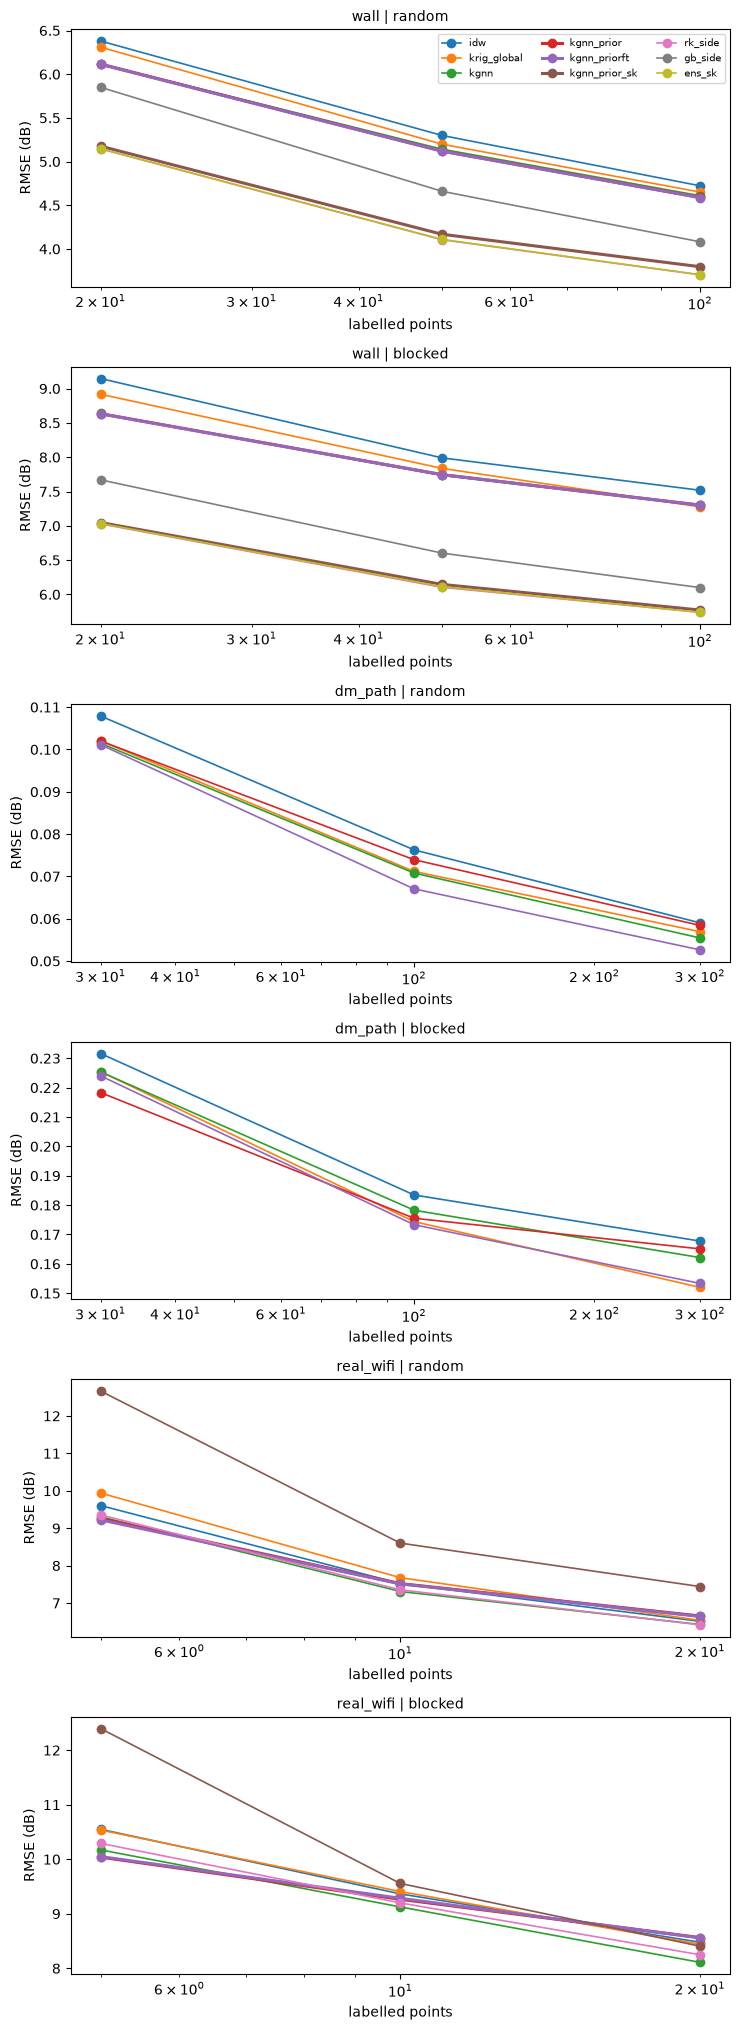

mean seconds per prediction job (training included: kgnn trains 150 steps per unit, kgnn_prior is zero-shot):


,seconds
name,
idw,0.004
kgnn_prior,0.006
kgnn_prior_rid,0.010
kgnn_prior_sk,0.012
rk_side,0.012
ens_sk,0.015
trend,0.088
kgnn_priorft,0.121
krig_global,0.172


230 contrast rows saved (all of them, losses included)


In [13]:
use = [(t, s) for (t, s) in RESULTS if t in ("real_wifi", "wall", "dm_path")]
fig, axes = plt.subplots(len(use), 1, figsize=(7.5, 3.4 * len(use)), squeeze=False)
show = ["idw", "krig_global", "kgnn", "kgnn_prior", "kgnn_priorft", "kgnn_prior_sk", "rk_side", "gb_geo", "gb_side", "ens_geo", "ens_sk"]
for ax, (t, s) in zip(axes[:, 0], use):
    tb = rx.agg_metric(RESULTS[(t, s)][RESULTS[(t, s)].status == "ok"], "rmse"); sc = tb.index.get_level_values(0)[0]; tb = tb.loc[sc]
    for m in [c for c in show if c in tb]: ax.plot(tb.index, tb[m], marker="o", label=m, lw=2.2 if m.startswith("kgnn_prior") else 1.2)
    ax.set_title(f"{t} | {s}", fontsize=10); ax.set_xlabel("labelled points"); ax.set_ylabel("RMSE (dB)"); ax.set_xscale("log")
axes[0, 0].legend(fontsize=7, ncol=3); plt.tight_layout(); plt.savefig(f"{ROOT}/regime.png", dpi=150); plt.show()
allr = pd.concat([d[d.status == "ok"] for (t, s), d in RESULTS.items() if t != "real_wifi"], ignore_index=True)
print("mean seconds per prediction job (training included: kgnn trains 150 steps per unit, kgnn_prior is zero-shot):"); display(allr.groupby("name").seconds.mean().round(3).sort_values().to_frame())
MASTER = r2.master_table(ENTRIES); MASTER.to_csv(f"{ROOT}/confirmatory_master_conf3.csv", index=False); print(len(MASTER), "contrast rows saved (all of them, losses included)")

## 7. What this round can and cannot establish
* **A pre-trained kernel is a prior, not a new architecture.** If `kgnn_prior` beats `kgnn`, the claim is "meta-learning the 6 kernel parameters across layouts improves few-label kriging attention"; it does not make GCN/GAT competitive.
* **The wall simulator is the author's own.** The shadowing field is independent of walls, so a wall-aware kernel has little to exploit; H7 is a stringent test of whether a learned kernel can add to ridge+IDW, not evidence about real buildings.
* **Six real buildings.** Building-level CIs are wide by construction; the smallest exact sign-test p is 0.031. The real-data claim is about consistency across buildings and effect size.
* **Wi-Fi at 2.4/5 GHz is not 6G.** Only DeepMIMO (2.5 / 28 / 60 GHz) touches higher bands and it has one environment per scenario: descriptive only, no prior, no claim. A 6G claim needs ray-traced scenes with many independent layouts at FR3 or sub-THz.
* **Priors are layout-disjoint; UJI/SOD floors and APs inside a held-out building are not.** Evaluation units of a held-out building share walls, hence the building-level table.
* **Absolute effects are small** (percent of an RMSE of 5-10 dB). Say so next to every headline.
* **Not tested:** a deep radio-map network trained on many layouts (e.g. RadioUNet-style) and kriging with the true AP position known (SOD ships it). A reviewer may ask for both.